In [2]:
import sys, subprocess
import importlib.metadata as md_

PACKAGES = ["ultralytics", "opencv-python-headless", "matplotlib", "pandas",
            "numpy", "pillow", "pyyaml", "streamlit"]

result = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PACKAGES],
                        capture_output=True, text=True)
if result.returncode != 0:
    print(result.stdout[-2000:])
    print(result.stderr[-3000:])
    raise RuntimeError("Package installation failed. See the pip messages above. "
                       "Check your internet connection, then re-run this cell.")

for pkg in PACKAGES:
    try:
        print(f"{pkg:<24} {md_.version(pkg)}")
    except md_.PackageNotFoundError:
        raise RuntimeError(f"Package '{pkg}' was not installed correctly. Re-run this cell.")
print("\nAll packages installed.")

ultralytics              8.4.199
opencv-python-headless   5.0.0.93
matplotlib               3.10.0
pandas                   2.2.3
numpy                    2.4.6
pillow                   11.3.0
pyyaml                   6.0.3
streamlit                1.66.1

All packages installed.


In [3]:
import os, shutil, json, random, time, zipfile
from pathlib import Path
import torch

BASE = Path("/content") if Path("/content").exists() else Path.cwd()   # Colab uses /content

DATASET_DIR = BASE / "helmet_dataset"          # where the ZIP is extracted
SPLIT_DIR   = BASE / "helmet_split"            # final 70/20/10 dataset (if a new split is needed)
PROJECT_DIR = BASE / "Helmet_Detection"        # training runs, models, outputs
MODELS_DIR  = PROJECT_DIR / "models"
OUTPUT_DIR  = PROJECT_DIR / "outputs"
FIG_DIR     = OUTPUT_DIR / "figures"
for d in (PROJECT_DIR, MODELS_DIR, OUTPUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    DEVICE = 0
    props = torch.cuda.get_device_properties(0)
    GPU_MEM_GB = props.total_memory / 1024**3
    print(f"GPU available: {props.name} | memory: {GPU_MEM_GB:.1f} GB")
else:
    DEVICE = "cpu"
    GPU_MEM_GB = 0.0
    print("WARNING: No GPU found. Training will use the CPU (very slow).")
    print("To enable a GPU: Runtime -> Change runtime type -> T4 GPU -> Save -> Restart session.")
print("Torch version:", torch.__version__, "| DEVICE =", DEVICE)
print("Working base folder:", BASE)

GPU available: Tesla T4 | memory: 14.6 GB
Torch version: 2.11.0+cu130 | DEVICE = 0
Working base folder: /content


In [4]:
from google.colab import files

FORCE_UPLOAD = False   # set True to upload a different ZIP

def looks_like_yolo_dataset(z):
    # a usable dataset ZIP must contain a data.yaml (this also skips our own backup/project ZIPs)
    try:
        with zipfile.ZipFile(z) as zf:
            return any(n.lower().endswith(("data.yaml", "data.yml")) for n in zf.namelist())
    except Exception:
        return False

def find_existing_zip(folder):
    for z in sorted(folder.glob("*.zip")):
        if zipfile.is_zipfile(z) and looks_like_yolo_dataset(z):
            return z
    return None

ZIP_PATH = None if FORCE_UPLOAD else find_existing_zip(BASE)

if ZIP_PATH is None:
    print("Please choose your Roboflow dataset ZIP file...")
    uploaded = files.upload()
    zip_names = [n for n in uploaded if n.lower().endswith(".zip")]
    if not zip_names:
        raise FileNotFoundError("No .zip file was uploaded. Run this cell again and select the "
                                "Roboflow YOLOv8 ZIP file.")
    uploaded_path = Path.cwd() / zip_names[0]
    ZIP_PATH = BASE / uploaded_path.name
    if uploaded_path.resolve() != ZIP_PATH.resolve():
        shutil.move(str(uploaded_path), str(ZIP_PATH))

if not ZIP_PATH.exists():
    raise FileNotFoundError(f"ZIP file not found: {ZIP_PATH}")
if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError(f"{ZIP_PATH.name} is not a valid ZIP file (incomplete download?). Download it again.")
if not looks_like_yolo_dataset(ZIP_PATH):
    raise ValueError(f"{ZIP_PATH.name} does not contain a data.yaml, so it is not a YOLO dataset export. "
                     "Export the dataset from Roboflow in 'YOLOv8' format and upload that ZIP.")

print(f"Using ZIP: {ZIP_PATH.name}  ({ZIP_PATH.stat().st_size / 1024**2:.1f} MB)")

Please choose your Roboflow dataset ZIP file...


Saving Helmet Motorcycle Detection.v1i.yolov8.zip to Helmet Motorcycle Detection.v1i.yolov8.zip
Using ZIP: Helmet Motorcycle Detection.v1i.yolov8.zip  (219.6 MB)


In [5]:
def safe_extract(zip_path, dest):
    # Extract a ZIP while blocking unsafe paths ('../') and checking for a corrupted archive.
    dest = Path(dest)
    if dest.exists():
        shutil.rmtree(dest)
    dest.mkdir(parents=True, exist_ok=True)
    dest_resolved = dest.resolve()
    with zipfile.ZipFile(zip_path) as z:
        bad = z.testzip()
        if bad is not None:
            raise RuntimeError(f"Corrupted file inside ZIP: {bad}. Download the dataset again.")
        for member in z.infolist():
            target = (dest / member.filename).resolve()
            if dest_resolved != target and dest_resolved not in target.parents:
                raise RuntimeError(f"Unsafe path in ZIP: {member.filename}")
        z.extractall(dest)
        return len(z.infolist())

def discover_dataset_root(base):
    yamls = [p for p in base.rglob("*") if p.is_file() and p.name.lower() in ("data.yaml", "data.yml")
             and "__MACOSX" not in p.parts]
    if not yamls:
        raise FileNotFoundError(
            "data.yaml was not found anywhere inside the ZIP. This does not look like a YOLO export. "
            "Export the dataset from Roboflow in 'YOLOv8' format and upload that ZIP.")
    yaml_path = min(yamls, key=lambda p: len(p.parts))      # the shallowest data.yaml
    return yaml_path.parent, yaml_path

n_members = safe_extract(ZIP_PATH, DATASET_DIR)
print(f"Extracted {n_members} entries into {DATASET_DIR}")

DATASET_ROOT, ORIG_YAML = discover_dataset_root(DATASET_DIR)
print("Dataset root:", DATASET_ROOT)
print("data.yaml   :", ORIG_YAML)
print("Folders in dataset root:", sorted(p.name for p in DATASET_ROOT.iterdir() if p.is_dir()))

Extracted 5874 entries into /content/helmet_dataset
Dataset root: /content/helmet_dataset
data.yaml   : /content/helmet_dataset/data.yaml
Folders in dataset root: ['test', 'train', 'valid']


In [6]:
import yaml
import pandas as pd
from collections import Counter, defaultdict

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLIT_ALIASES = {"train": ["train"], "val": ["valid", "val", "validation"], "test": ["test"]}

# ---------- 1. read data.yaml -------------------------------------------------
with open(ORIG_YAML, "r", encoding="utf-8") as f:
    orig_cfg = yaml.safe_load(f)

raw_names = orig_cfg.get("names")
if raw_names is None:
    raise ValueError("data.yaml has no 'names' entry, so the classes cannot be identified.")
if isinstance(raw_names, dict):
    CLASS_NAMES = [raw_names[k] for k in sorted(raw_names, key=int)]
else:
    CLASS_NAMES = list(raw_names)
NC = len(CLASS_NAMES)
if "nc" in orig_cfg and int(orig_cfg["nc"]) != NC:
    print(f"WARNING: nc={orig_cfg['nc']} in data.yaml but {NC} names listed. Using the names list.")

print("Original data.yaml contents:")
print(yaml.safe_dump(orig_cfg, sort_keys=False))
print("Classes found (ID -> name):")
for i, n in enumerate(CLASS_NAMES):
    print(f"   {i} -> {n}")
absence_words = ("no helmet", "no_helmet", "nohelmet", "without", "no-helmet", "without helmet")
HAS_ABSENCE_CLASS = any(any(w in str(n).lower() for w in absence_words) for n in CLASS_NAMES)
if not HAS_ABSENCE_CLASS:
    print("\nIMPORTANT: this dataset has NO 'No Helmet' class. The model will be a "
          f"{NC}-class detector for: {CLASS_NAMES}.")
    print("It can find helmets, but it cannot report 'rider without helmet'. Detecting helmet "
          "absence needs extra, correctly labelled 'No Helmet' data.")

# ---------- 2. locate split folders ------------------------------------------
def find_split_dirs(root):
    found = {}
    for split, aliases in SPLIT_ALIASES.items():
        for a in aliases:
            candidates = [(root / a / "images", root / a / "labels"),      # root/train/images
                          (root / "images" / a, root / "labels" / a)]      # root/images/train
            for img_dir, lbl_dir in candidates:
                if img_dir.is_dir():
                    found[split] = (img_dir, lbl_dir)
                    break
            if split in found:
                break
    return found

def list_images(folder):
    return sorted(p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXTS)

def validate_label_file(path, nc):
    # Returns (n_boxes, list_of_problems). An EMPTY file is valid YOLO (= background image).
    problems, n = [], 0
    try:
        text = path.read_text(encoding="utf-8").strip()
    except Exception as e:
        return 0, [f"cannot read file: {e}"]
    for ln, line in enumerate(text.splitlines(), 1):
        if not line.strip():
            continue
        parts = line.split()
        if len(parts) != 5:
            problems.append(f"line {ln}: expected 5 values, found {len(parts)}")
            continue
        try:
            cid = int(parts[0]); vals = [float(x) for x in parts[1:]]
        except ValueError:
            problems.append(f"line {ln}: non-numeric value"); continue
        if not (0 <= cid < nc):
            problems.append(f"line {ln}: class ID {cid} outside 0..{nc-1}")
        if any(v < 0 or v > 1 for v in vals):
            problems.append(f"line {ln}: coordinates must be between 0 and 1")
        if vals[2] <= 0 or vals[3] <= 0:
            problems.append(f"line {ln}: box width/height must be > 0")
        if not problems:
            n += 1
    return n, problems

def source_key(stem):
    # Roboflow names augmented files '<original>.rf.<hash>'. Copies of one photo share <original>.
    return stem.split(".rf.")[0]

def scan_split(img_dir, lbl_dir, nc):
    info = dict(pairs=[], missing_labels=[], orphan_labels=[], invalid=[], empty=[], class_counts=Counter(),
                boxes_per_image=[])
    imgs = list_images(img_dir) if img_dir.is_dir() else []
    lbls = {p.stem: p for p in lbl_dir.glob("*.txt")} if lbl_dir.is_dir() else {}
    for img in imgs:
        lbl = lbls.pop(img.stem, None)
        if lbl is None:
            info["missing_labels"].append(img); continue
        n, problems = validate_label_file(lbl, nc)
        if problems:
            info["invalid"].append((lbl, problems)); continue
        if n == 0:
            info["empty"].append(lbl)
        for line in lbl.read_text().strip().splitlines():
            if line.strip():
                info["class_counts"][int(line.split()[0])] += 1
        info["boxes_per_image"].append(n)
        info["pairs"].append(dict(img=img, lbl=lbl, group=source_key(img.stem)))
    info["orphan_labels"] = list(lbls.values())            # labels with no image
    info["n_images"] = len(imgs)
    info["n_label_files"] = len(imgs) - len(info["missing_labels"]) + len(info["orphan_labels"])
    return info

ORIG_SPLITS = find_split_dirs(DATASET_ROOT)
if not ORIG_SPLITS:
    raise FileNotFoundError("Could not find train/valid/test image folders inside "
                            f"{DATASET_ROOT}. Folders present: {[p.name for p in DATASET_ROOT.iterdir()]}")
if "train" not in ORIG_SPLITS:
    raise FileNotFoundError("No training folder found. At least a 'train' folder with images is required.")

ORIG_SCAN = {s: scan_split(i, l, NC) for s, (i, l) in ORIG_SPLITS.items()}

rows = []
for s, info in ORIG_SCAN.items():
    rows.append({"split": s, "images": info["n_images"], "label files": info["n_label_files"],
                 "valid pairs": len(info["pairs"]), "images w/o label": len(info["missing_labels"]),
                 "labels w/o image": len(info["orphan_labels"]), "invalid label files": len(info["invalid"]),
                 "empty label files": len(info["empty"]),
                 "boxes": sum(info["class_counts"].values())})
orig_df = pd.DataFrame(rows).set_index("split")
total_valid = int(orig_df["valid pairs"].sum())
orig_df["share of valid pairs (%)"] = (orig_df["valid pairs"] / max(total_valid, 1) * 100).round(1)
print("\nORIGINAL split inspection:")
display(orig_df)
for s in ("train", "val", "test"):
    if s not in ORIG_SPLITS:
        print(f"NOTE: no '{s}' folder found in the original dataset.")

# ---------- 3. report problems (nothing is changed) ----------------------------
problem_found = False
for s, info in ORIG_SCAN.items():
    for img in info["missing_labels"][:5]:
        print(f"[{s}] image without label file: {img.name}"); problem_found = True
    for lbl in info["orphan_labels"][:5]:
        print(f"[{s}] label without image: {lbl.name}"); problem_found = True
    for lbl, probs in info["invalid"][:5]:
        print(f"[{s}] INVALID label {lbl.name}: {probs[:2]}"); problem_found = True
    if len(info["missing_labels"]) > 5 or len(info["invalid"]) > 5:
        print(f"[{s}] ... more problems exist; see the counts in the table above.")
if not problem_found:
    print("\nLabel check: every image has a label file and all annotation lines are valid.")
else:
    print("\nProblem images/labels are reported above. They will be EXCLUDED from training "
          "(not edited) in Section 6.")

# ---------- 4. augmentation-leakage check on the ORIGINAL split ------------------
src_to_splits = defaultdict(set)
for s, info in ORIG_SCAN.items():
    for p in info["pairs"]:
        src_to_splits[p["group"]].add(s)
ORIG_LEAK = sorted(k for k, v in src_to_splits.items() if len(v) > 1)
n_sources = len(src_to_splits)
print(f"\nUnique source photos: {n_sources} for {total_valid} images "
      f"(about {total_valid / max(n_sources,1):.1f} images per source because of augmentation).")
print(f"Source photos that appear in MORE THAN ONE split (leakage): {len(ORIG_LEAK)}")
if ORIG_LEAK:
    print("   Example:", ORIG_LEAK[0][:60], "->", sorted(src_to_splits[ORIG_LEAK[0]]))

Original data.yaml contents:
train: ../train/images
val: ../valid/images
test: ../test/images
nc: 1
names:
- Helmet
roboflow:
  workspace: computer-vision-vxgzc
  project: helmet-motorcycle-detection-pro0q
  version: 1
  license: Public Domain
  url: https://universe.roboflow.com/computer-vision-vxgzc/helmet-motorcycle-detection-pro0q/dataset/1

Classes found (ID -> name):
   0 -> Helmet

IMPORTANT: this dataset has NO 'No Helmet' class. The model will be a 1-class detector for: ['Helmet'].
It can find helmets, but it cannot report 'rider without helmet'. Detecting helmet absence needs extra, correctly labelled 'No Helmet' data.

ORIGINAL split inspection:


,images,label files,valid pairs,images w/o label,labels w/o image,invalid label files,empty label files,boxes,share of valid pairs (%)
split,,,,,,,,,
train,2703,2703,2703,0,0,0,0,11088,92.2
val,114,114,114,0,0,0,0,130,3.9
test,114,114,114,0,0,0,0,115,3.9



Label check: every image has a label file and all annotation lines are valid.

Unique source photos: 992 for 2931 images (about 3.0 images per source because of augmentation).
Source photos that appear in MORE THAN ONE split (leakage): 25
   Example: -original-imagfcjaf5yympj7_jpeg_jpg -> ['train', 'val']


In [7]:
TARGET = {"train": 0.70, "val": 0.20, "test": 0.10}
TOLERANCE = 0.02
SEED = 42

def current_ratios():
    return {s: len(ORIG_SCAN[s]["pairs"]) / max(total_valid, 1) for s in ORIG_SCAN}

ratios = current_ratios()
has_all = all(s in ORIG_SCAN for s in TARGET)
ratio_ok = has_all and all(abs(ratios[s] - TARGET[s]) <= TOLERANCE for s in TARGET)
leak_free = len(ORIG_LEAK) == 0
KEEP_ORIGINAL = ratio_ok and leak_free

print("Existing ratios:", {s: f"{r*100:.1f}%" for s, r in ratios.items()})
print("Target ratios  :", {s: f"{r*100:.0f}%" for s, r in TARGET.items()})
print(f"Ratio close to 70:20:10? {ratio_ok} | No leakage? {leak_free}")

def write_data_yaml(path, split_img_dirs, root=None):
    cfg = {}
    if root is not None:
        cfg["path"] = str(root)
    cfg.update({k: str(v) for k, v in split_img_dirs.items()})
    cfg["nc"] = NC
    cfg["names"] = {i: n for i, n in enumerate(CLASS_NAMES)}
    with open(path, "w", encoding="utf-8") as f:
        yaml.safe_dump(cfg, f, sort_keys=False, allow_unicode=True)
    return path

if KEEP_ORIGINAL:
    print("\nThe original split is already ~70:20:10 with no leakage -> keeping it.")
    FINAL_SPLITS = {s: ORIG_SPLITS[s] for s in TARGET}
    DATA_YAML = write_data_yaml(BASE / "helmet_data.yaml", {s: FINAL_SPLITS[s][0] for s in TARGET})
else:
    print("\nCreating a NEW reproducible group-aware 70:20:10 split (seed = %d) ..." % SEED)
    all_pairs = []
    for s, info in ORIG_SCAN.items():
        for p in info["pairs"]:
            all_pairs.append({**p, "orig_split": s})
    if len(all_pairs) < 30:
        raise ValueError(f"Not enough valid image/label pairs to split ({len(all_pairs)}). "
                         "Check the problems reported in Section 5.")

    groups = defaultdict(list)
    for p in all_pairs:
        groups[p["group"]].append(p)
    keys = sorted(groups)
    random.Random(SEED).shuffle(keys)

    n_total = len(all_pairs)
    goal = {s: TARGET[s] * n_total for s in TARGET}
    assigned = {s: [] for s in TARGET}
    counts = {s: 0 for s in TARGET}
    for k in keys:                                   # give each group to the split furthest below its goal
        best = max(TARGET, key=lambda s: (goal[s] - counts[s]) / goal[s])
        assigned[best].extend(groups[k])
        counts[best] += len(groups[k])

    if SPLIT_DIR.exists():
        shutil.rmtree(SPLIT_DIR)
    used_names = set()
    for s, items in assigned.items():
        (SPLIT_DIR / s / "images").mkdir(parents=True, exist_ok=True)
        (SPLIT_DIR / s / "labels").mkdir(parents=True, exist_ok=True)
        for p in items:
            stem = p["img"].stem
            if stem in used_names:                   # same file name in two original splits
                stem = f"{p['orig_split']}_{stem}"
            used_names.add(stem)
            shutil.copy2(p["img"], SPLIT_DIR / s / "images" / (stem + p["img"].suffix))
            shutil.copy2(p["lbl"], SPLIT_DIR / s / "labels" / (stem + ".txt"))

    FINAL_SPLITS = {s: (SPLIT_DIR / s / "images", SPLIT_DIR / s / "labels") for s in TARGET}
    DATA_YAML = write_data_yaml(SPLIT_DIR / "data.yaml",
                                {s: f"{s}/images" for s in TARGET}, root=SPLIT_DIR)

    excluded = sum(len(i["missing_labels"]) + len(i["invalid"]) for i in ORIG_SCAN.values())
    print(f"Copied {n_total} image/label pairs. Excluded (missing/invalid labels): {excluded}")

# ---------- verify the final split --------------------------------------------
FINAL_SCAN = {s: scan_split(i, l, NC) for s, (i, l) in FINAL_SPLITS.items()}
final_total = sum(len(v["pairs"]) for v in FINAL_SCAN.values())
final_groups = defaultdict(set)
for s, info in FINAL_SCAN.items():
    for p in info["pairs"]:
        final_groups[p["group"]].add(s)
leak = [k for k, v in final_groups.items() if len(v) > 1]
names_seen = defaultdict(set)
for s, info in FINAL_SCAN.items():
    for p in info["pairs"]:
        names_seen[p["img"].name].add(s)
name_leak = [k for k, v in names_seen.items() if len(v) > 1]

rows = []
for s, info in FINAL_SCAN.items():
    rows.append({"split": s, "images": len(info["pairs"]),
                 "share (%)": round(len(info["pairs"]) / final_total * 100, 1),
                 "source photos": len({p['group'] for p in info['pairs']}),
                 "boxes": sum(info["class_counts"].values()),
                 "invalid labels": len(info["invalid"]), "missing labels": len(info["missing_labels"])})
final_df = pd.DataFrame(rows).set_index("split")
print("\nFINAL split:")
display(final_df)
print(f"Leakage between splits (same source photo): {len(leak)}")
print(f"Leakage between splits (same file name)   : {len(name_leak)}")
if leak or name_leak:
    raise RuntimeError("Leakage detected in the final split. Do not train; check the grouping logic.")
if any(len(v["invalid"]) or len(v["missing_labels"]) for v in FINAL_SCAN.values()):
    raise RuntimeError("The final split contains invalid or unpaired labels. Review Section 5 output.")

print("\nClass IDs used in labels:", {k: dict(v["class_counts"]) for k, v in FINAL_SCAN.items()})
print("\nFinal data.yaml:", DATA_YAML)
print(Path(DATA_YAML).read_text())

Existing ratios: {'train': '92.2%', 'val': '3.9%', 'test': '3.9%'}
Target ratios  : {'train': '70%', 'val': '20%', 'test': '10%'}
Ratio close to 70:20:10? False | No leakage? False

Creating a NEW reproducible group-aware 70:20:10 split (seed = 42) ...
Copied 2931 image/label pairs. Excluded (missing/invalid labels): 0

FINAL split:


,images,share (%),source photos,boxes,invalid labels,missing labels
split,,,,,,
train,2043,69.7,701,7956,0,0
val,594,20.3,192,2257,0,0
test,294,10.0,99,1120,0,0


Leakage between splits (same source photo): 0
Leakage between splits (same file name)   : 0

Class IDs used in labels: {'train': {0: 7956}, 'val': {0: 2257}, 'test': {0: 1120}}

Final data.yaml: /content/helmet_split/data.yaml
path: /content/helmet_split
train: train/images
val: val/images
test: test/images
nc: 1
names:
  0: Helmet



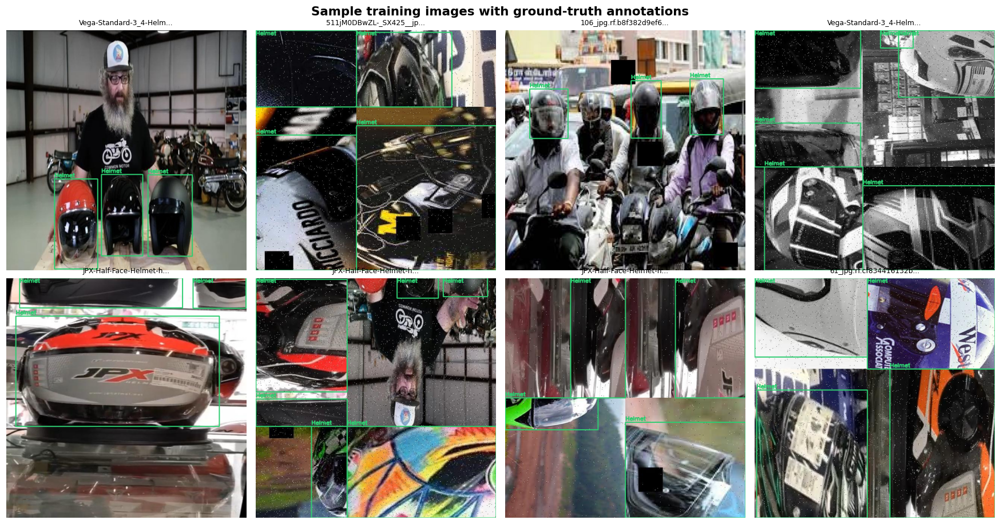

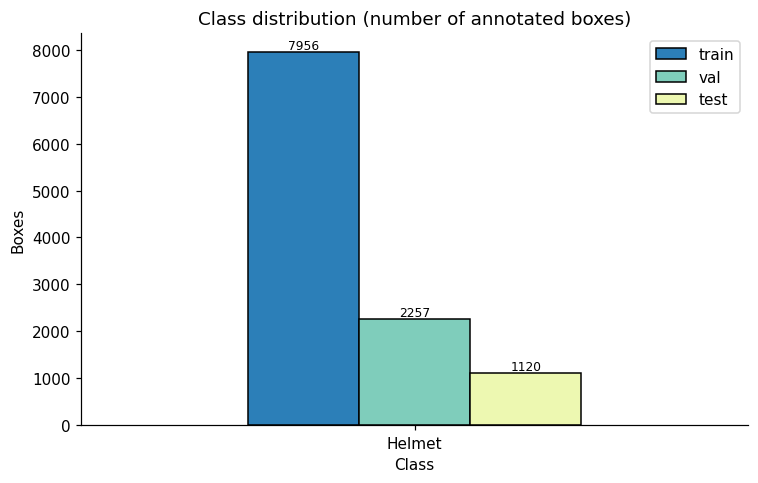

,train,val,test
Helmet,7956,2257,1120


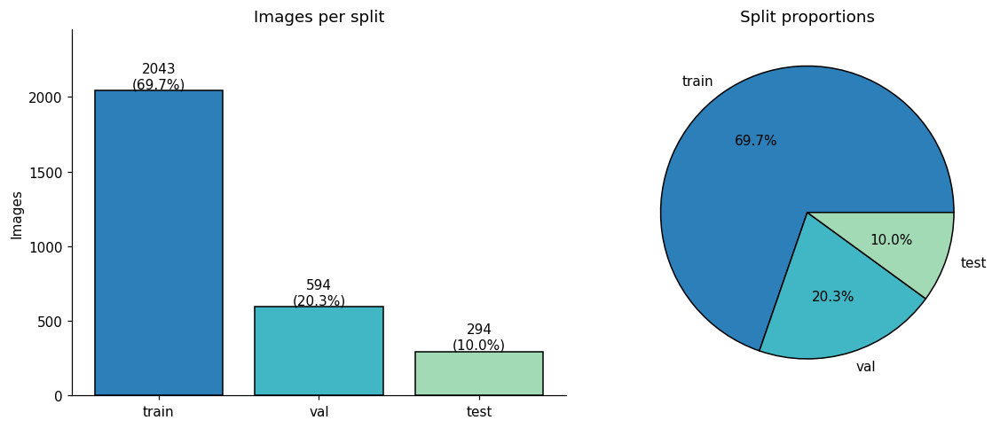

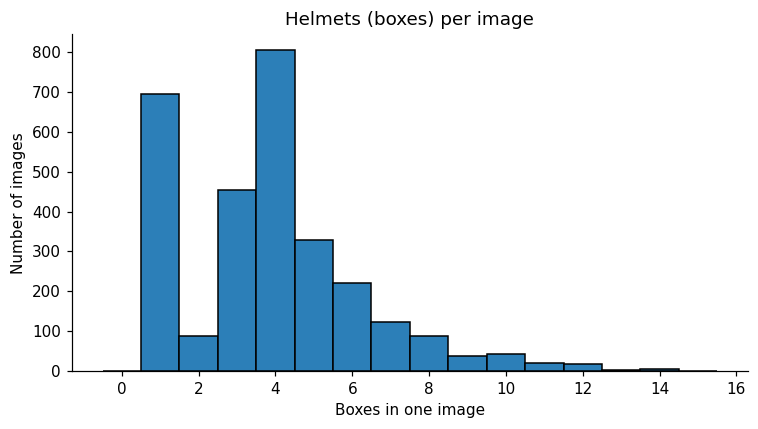

Average boxes per image: 3.87


In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
PALETTE = [(46, 204, 113), (231, 76, 60), (52, 152, 219), (241, 196, 15)]    # RGB

def read_yolo_boxes(lbl_path, w, h):
    boxes = []
    for line in lbl_path.read_text().strip().splitlines():
        if not line.strip():
            continue
        c, xc, yc, bw, bh = line.split()
        c = int(c); xc, yc, bw, bh = (float(xc) * w, float(yc) * h, float(bw) * w, float(bh) * h)
        boxes.append((c, int(xc - bw / 2), int(yc - bh / 2), int(xc + bw / 2), int(yc + bh / 2)))
    return boxes

# ---- Figure 1: sample training images with ground-truth boxes ----
train_pairs = FINAL_SCAN["train"]["pairs"]
rng = random.Random(SEED)
sample = rng.sample(train_pairs, min(8, len(train_pairs)))
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for ax, p in zip(axes.ravel(), sample):
    img = cv2.imread(str(p["img"]))
    if img is None:
        print("Could not read image (skipped):", p["img"].name); ax.axis("off"); continue
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for c, x1, y1, x2, y2 in read_yolo_boxes(p["lbl"], w, h):
        col = PALETTE[c % len(PALETTE)]
        cv2.rectangle(img, (x1, y1), (x2, y2), col, 2)
        cv2.putText(img, CLASS_NAMES[c], (x1, max(y1 - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, col, 2)
    ax.imshow(img); ax.axis("off"); ax.set_title(p["img"].name[:22] + "...", fontsize=8)
for ax in axes.ravel()[len(sample):]:
    ax.axis("off")
fig.suptitle("Sample training images with ground-truth annotations", fontsize=14, fontweight="bold")
plt.tight_layout(); fig.savefig(FIG_DIR / "01_sample_images.png", bbox_inches="tight"); plt.show()

# ---- Figure 2: class distribution (number of boxes per class, per split) ----
cls_df = pd.DataFrame({s: [FINAL_SCAN[s]["class_counts"].get(i, 0) for i in range(NC)] for s in FINAL_SCAN},
                      index=CLASS_NAMES)
ax = cls_df.plot(kind="bar", figsize=(7, 4.5), rot=0, color=["#2c7fb8", "#7fcdbb", "#edf8b1"][:cls_df.shape[1]],
                 edgecolor="black")
ax.set_title("Class distribution (number of annotated boxes)"); ax.set_ylabel("Boxes"); ax.set_xlabel("Class")
for cont in ax.containers:
    ax.bar_label(cont, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "02_class_distribution.png", bbox_inches="tight"); plt.show()
display(cls_df)

# ---- Figure 3: split statistics ----
counts = final_df["images"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.5))
bars = a1.bar(counts.index, counts.values, color=["#2c7fb8", "#41b6c4", "#a1dab4"], edgecolor="black")
for b, v in zip(bars, counts.values):
    a1.text(b.get_x() + b.get_width() / 2, v, f"{v}\n({v/counts.sum()*100:.1f}%)", ha="center", va="bottom")
a1.set_title("Images per split"); a1.set_ylabel("Images"); a1.set_ylim(0, counts.max() * 1.2)
a2.pie(counts.values, labels=counts.index, autopct="%1.1f%%", colors=["#2c7fb8", "#41b6c4", "#a1dab4"],
       wedgeprops={"edgecolor": "black"})
a2.set_title("Split proportions")
plt.tight_layout(); fig.savefig(FIG_DIR / "03_split_statistics.png", bbox_inches="tight"); plt.show()

# ---- Figure 4: boxes per image ----
bpi = [n for s in FINAL_SCAN for n in FINAL_SCAN[s]["boxes_per_image"]]
plt.figure(figsize=(7, 4))
plt.hist(bpi, bins=range(0, max(bpi) + 2), color="#2c7fb8", edgecolor="black", align="left")
plt.title("Helmets (boxes) per image"); plt.xlabel("Boxes in one image"); plt.ylabel("Number of images")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_boxes_per_image.png", bbox_inches="tight"); plt.show()
print(f"Average boxes per image: {np.mean(bpi):.2f}")

DATA_STATS = {"images": {s: int(len(FINAL_SCAN[s]['pairs'])) for s in FINAL_SCAN},
              "boxes": {s: int(sum(FINAL_SCAN[s]['class_counts'].values())) for s in FINAL_SCAN},
              "original_images": int(total_valid), "original_split": {s: int(len(ORIG_SCAN[s]['pairs'])) for s in ORIG_SCAN},
              "kept_original_split": bool(KEEP_ORIGINAL)}

In [9]:
from ultralytics import YOLO

EPOCHS   = 50          # on CPU you may want 10
IMGSZ    = 640
PATIENCE = 15
WORKERS  = 2
RUN_NAME = "custom_yolov8"
TRAIN_EXTRA = {}       # optional extra Ultralytics arguments, e.g. {"fraction": 0.1} for a quick test run

def choose_batch(gpu_gb):
    if gpu_gb == 0:  return 4         # CPU
    if gpu_gb >= 22: return 32
    if gpu_gb >= 14: return 32        # T4 (15 GB) is fine for yolov8n at 640
    if gpu_gb >= 8:  return 16
    return 8

BATCH = choose_batch(GPU_MEM_GB)      # you can override this, e.g. BATCH = 8
if not Path(DATA_YAML).exists():
    raise FileNotFoundError(f"data.yaml not found at {DATA_YAML}. Run Sections 3-6 first.")
if DEVICE == "cpu":
    print("WARNING: training on CPU. Consider EPOCHS = 10 and be prepared for a long wait.\n")
print(f"Device: {DEVICE} | batch: {BATCH} | epochs: {EPOCHS} | imgsz: {IMGSZ}")

def is_oom(err):
    return isinstance(err, torch.cuda.OutOfMemoryError) or "out of memory" in str(err).lower()

TRAINED_MODEL = None
SAVE_DIR = None
batch = BATCH
while True:
    try:
        model = YOLO("yolov8n.pt")                      # pretrained COCO weights (downloaded automatically)
        model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=batch, workers=WORKERS,
                    device=DEVICE, patience=PATIENCE, optimizer="auto", project=str(PROJECT_DIR),
                    name=RUN_NAME, exist_ok=True, seed=0, plots=True, **TRAIN_EXTRA)
        TRAINED_MODEL = model
        SAVE_DIR = Path(model.trainer.save_dir)
        break
    except Exception as err:
        if is_oom(err) and batch > 2:
            batch //= 2
            print(f"\nCUDA out of memory. Retrying with batch size {batch} ...\n")
            del model
            torch.cuda.empty_cache()
            continue
        if is_oom(err):
            raise RuntimeError("CUDA out of memory even with a tiny batch. Lower IMGSZ (e.g. 512) or restart "
                               "the runtime and try again.") from err
        raise

BATCH = batch
print("\nTraining finished. Results folder:", SAVE_DIR)
print("Weights folder contents:", sorted(p.name for p in (SAVE_DIR / 'weights').glob('*')))

Device: 0 | batch: 32 | epochs: 50 | imgsz: 640
New https://pypi.org/project/ultralytics/8.4.200 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/helmet_split/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300,

In [10]:
def locate_weights(save_dir, filename):
    candidate = Path(save_dir) / "weights" / filename
    if candidate.exists():
        return candidate
    found = sorted(PROJECT_DIR.rglob(filename), key=lambda p: p.stat().st_mtime, reverse=True)
    found = [p for p in found if MODELS_DIR not in p.parents]
    return found[0] if found else None

if SAVE_DIR is None:
    runs = sorted(PROJECT_DIR.glob(RUN_NAME + "*"), key=lambda p: p.stat().st_mtime)
    if not runs:
        raise FileNotFoundError("No training run found. Run Section 8 first.")
    SAVE_DIR = runs[-1]
    print("Using existing run folder:", SAVE_DIR)

best_src = locate_weights(SAVE_DIR, "best.pt")
if best_src is None:
    raise FileNotFoundError("best.pt was not found. Training probably did not complete. "
                            "Re-run Section 8 and wait for 'Training finished'.")
BEST_PT = MODELS_DIR / "best.pt"
shutil.copy2(best_src, BEST_PT)
print("Saved:", BEST_PT, f"({BEST_PT.stat().st_size / 1024**2:.1f} MB)")

last_src = locate_weights(SAVE_DIR, "last.pt")
if last_src is not None:
    shutil.copy2(last_src, MODELS_DIR / "last.pt"); print("Saved:", MODELS_DIR / "last.pt")
else:
    print("WARNING: last.pt not found (not required for inference).")

RESULTS_SAVE = PROJECT_DIR / "saved_results"
if RESULTS_SAVE.exists():
    shutil.rmtree(RESULTS_SAVE)
RESULTS_SAVE.mkdir(parents=True)
copied = []
for pattern in ("results.csv", "results.png", "args.yaml", "confusion_matrix*.png", "*curve*.png",
                "labels*.jpg", "train_batch*.jpg", "val_batch*_pred.jpg"):
    for f in SAVE_DIR.glob(pattern):
        shutil.copy2(f, RESULTS_SAVE / f.name); copied.append(f.name)
print(f"Saved {len(copied)} result files to {RESULTS_SAVE}")
for must_have in ("results.csv", "results.png"):
    if must_have not in copied:
        print(f"WARNING: {must_have} was not found in the run folder.")
if not any(c.startswith("confusion_matrix") for c in copied):
    print("WARNING: no confusion matrix image in the training run folder (it will be generated in Section 10).")

BACKUP_STAGE = BASE / "_backup_stage"
if BACKUP_STAGE.exists():
    shutil.rmtree(BACKUP_STAGE)
shutil.copytree(MODELS_DIR, BACKUP_STAGE / "models")
shutil.copytree(RESULTS_SAVE, BACKUP_STAGE / "saved_results")
BACKUP_ZIP = Path(shutil.make_archive(str(BASE / "Helmet_Detection_model_and_results"), "zip", BACKUP_STAGE))
shutil.rmtree(BACKUP_STAGE)
print(f"\nBackup ZIP: {BACKUP_ZIP} ({BACKUP_ZIP.stat().st_size / 1024**2:.1f} MB)")
print("Download it from the Colab file browser (left sidebar) or run:  files.download(str(BACKUP_ZIP))")

Saved: /content/Helmet_Detection/models/best.pt (6.2 MB)
Saved: /content/Helmet_Detection/models/last.pt
Saved 19 result files to /content/Helmet_Detection/saved_results

Backup ZIP: /content/Helmet_Detection_model_and_results.zip (18.2 MB)
Download it from the Colab file browser (left sidebar) or run:  files.download(str(BACKUP_ZIP))


Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1772.1±383.9 MB/s, size: 71.5 KB)
val: Scanning /content/helmet_split/test/labels... 294 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 294/294 1.9Kit/s 0.2s
val: New cache created: /content/helmet_split/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 1.9it/s 5.2s
                   all        294       1120      0.943      0.978      0.988      0.943
Speed: 3.6ms preprocess, 4.8ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/Helmet_Detection/test_evaluation
Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.

,TEST set,VALIDATION set
Precision,0.9431,0.9572
Recall,0.9777,0.9512
F1,0.9601,0.9542
mAP50,0.9884,0.9883
mAP50-95,0.9433,0.9388


Test images evaluated: 294


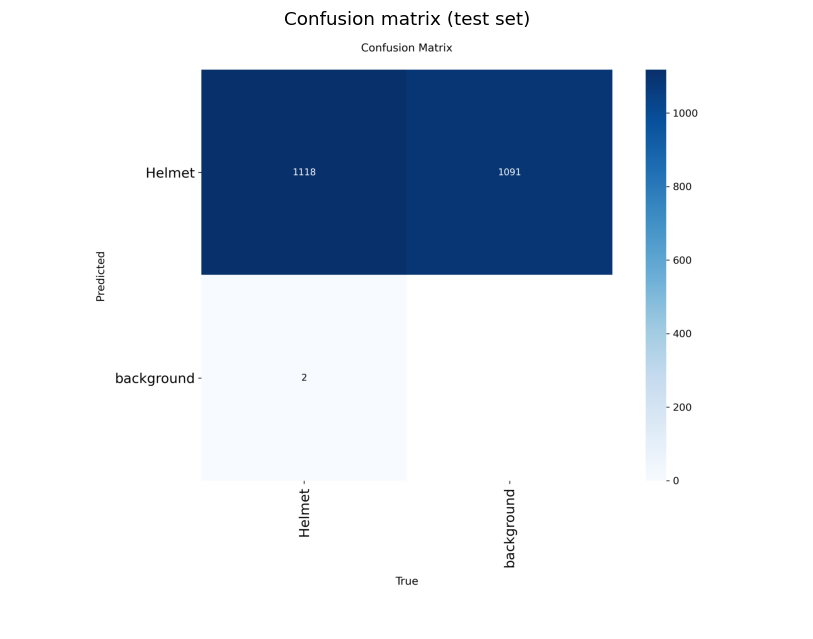

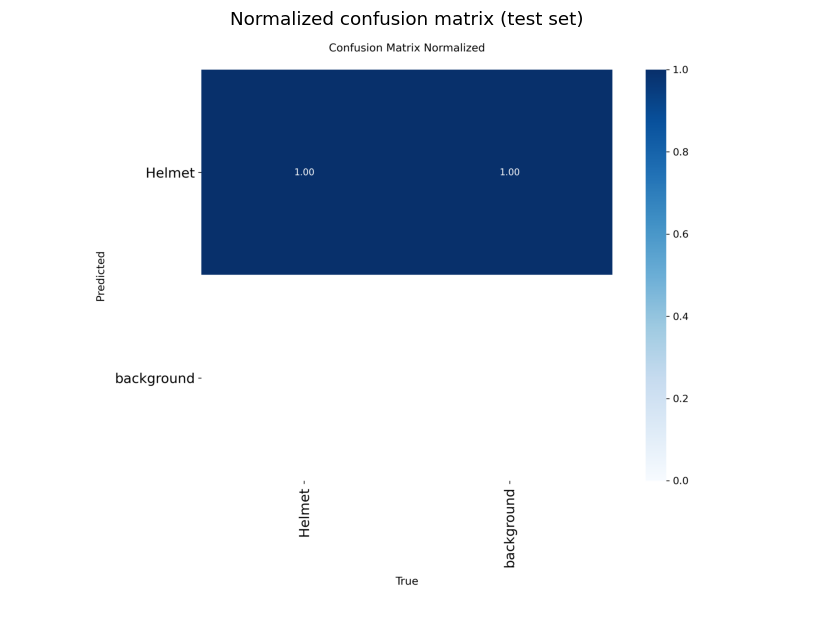

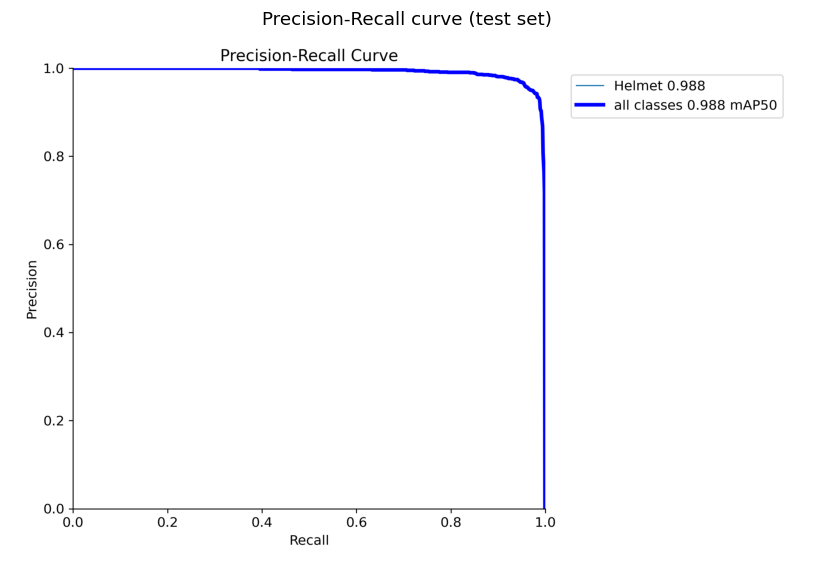

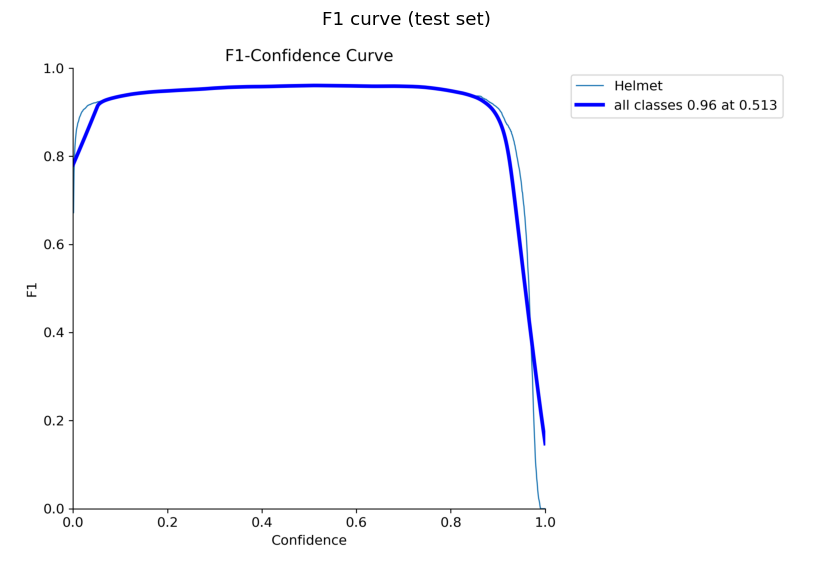

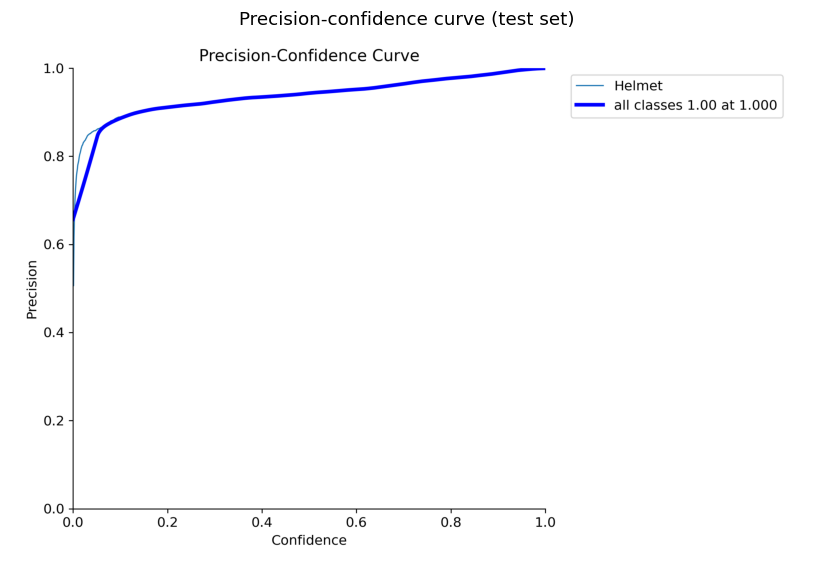

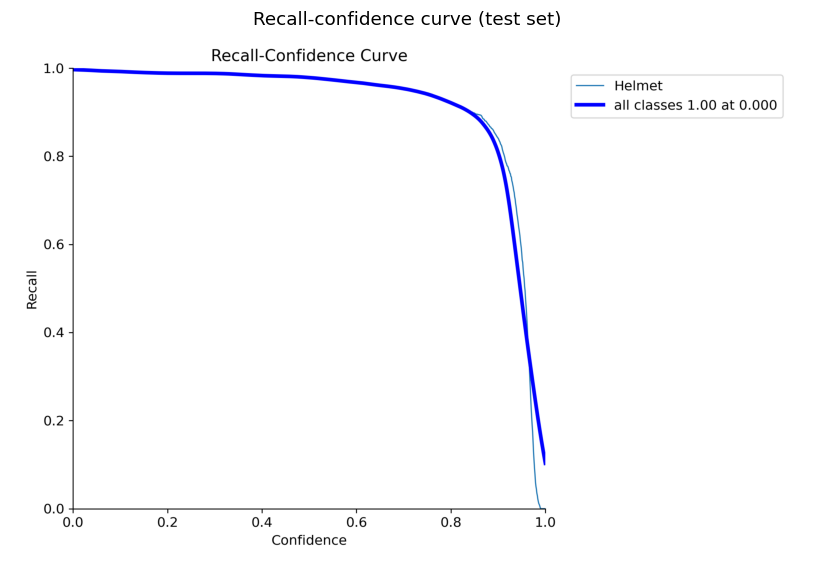

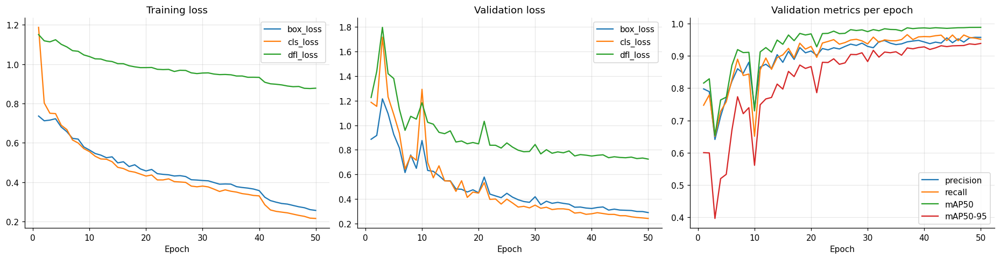

Epochs actually trained: 50 (maximum allowed: 50)


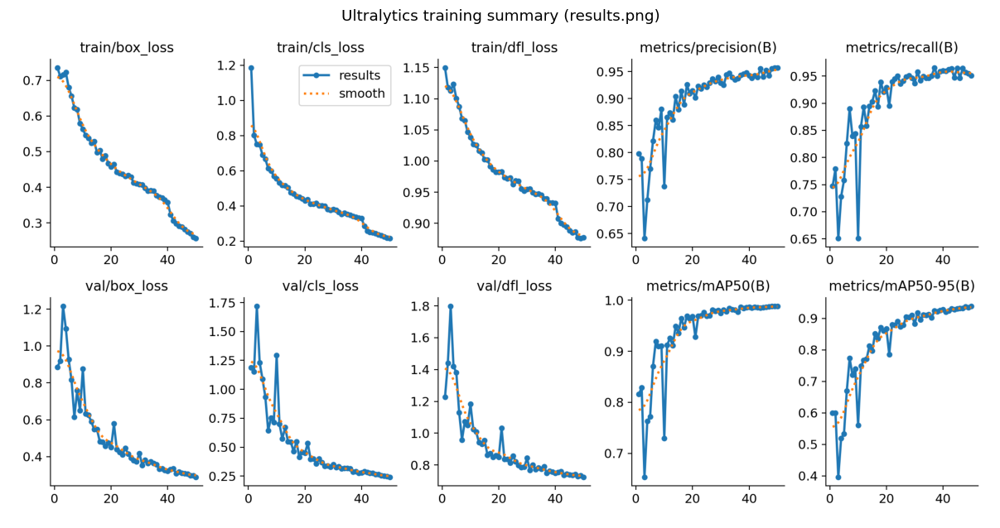


Model parameters: 3,138,003


In [11]:
if not BEST_PT.exists():
    raise FileNotFoundError(f"{BEST_PT} not found. Run Section 9 first.")
if len(FINAL_SCAN["test"]["pairs"]) == 0:
    raise ValueError("The test split is empty. Re-check Section 6.")

eval_model = YOLO(str(BEST_PT))

def evaluate(split_name, run_name):
    m = eval_model.val(data=str(DATA_YAML), split=split_name, imgsz=IMGSZ, batch=max(BATCH, 2), device=DEVICE,
                       project=str(PROJECT_DIR), name=run_name, exist_ok=True, plots=True, verbose=False)
    p, r = float(m.box.mp), float(m.box.mr)
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    return m, {"Precision": p, "Recall": r, "F1": f1, "mAP50": float(m.box.map50), "mAP50-95": float(m.box.map)}

test_m,  TEST_METRICS = evaluate("test", "test_evaluation")
val_m,   VAL_METRICS  = evaluate("val",  "val_evaluation")

metrics_df = pd.DataFrame({"TEST set": TEST_METRICS, "VALIDATION set": VAL_METRICS}).round(4)
print("Evaluation of best.pt (real values from this run):")
display(metrics_df)
print(f"Test images evaluated: {DATA_STATS['images']['test']}")

# ---- plots produced by the evaluation -------------------------------------
import re
import matplotlib.image as mpimg
EVAL_DIR = Path(test_m.save_dir)

def show_first(patterns, title, folder=EVAL_DIR):
    for pat in patterns:
        hits = sorted(folder.glob(pat))
        if hits:
            plt.figure(figsize=(7.5, 6)); plt.imshow(mpimg.imread(hits[0])); plt.axis("off"); plt.title(title)
            plt.tight_layout(); plt.savefig(FIG_DIR / (re.sub(r"[^a-z0-9]+", "_", title.lower()).strip("_") + ".png"), bbox_inches="tight")
            plt.show(); return hits[0]
    print(f"(No image found for: {title}. Looked in {folder} for {patterns})")

show_first(["confusion_matrix.png"], "Confusion matrix (test set)")
show_first(["confusion_matrix_normalized.png"], "Normalized confusion matrix (test set)")
show_first(["BoxPR_curve.png", "PR_curve.png"], "Precision-Recall curve (test set)")
show_first(["BoxF1_curve.png", "F1_curve.png"], "F1 curve (test set)")
show_first(["BoxP_curve.png", "P_curve.png"], "Precision-confidence curve (test set)")
show_first(["BoxR_curve.png", "R_curve.png"], "Recall-confidence curve (test set)")

# ---- training loss + validation metric curves from results.csv ------------
csv_path = SAVE_DIR / "results.csv"
if not csv_path.exists():
    print("results.csv not found; cannot draw the training curves.")
else:
    hist = pd.read_csv(csv_path)
    hist.columns = [c.strip() for c in hist.columns]
    ep = hist["epoch"]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for col in ("train/box_loss", "train/cls_loss", "train/dfl_loss"):
        if col in hist: axes[0].plot(ep, hist[col], label=col.split("/")[1])
    axes[0].set_title("Training loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=.3)
    for col in ("val/box_loss", "val/cls_loss", "val/dfl_loss"):
        if col in hist: axes[1].plot(ep, hist[col], label=col.split("/")[1])
    axes[1].set_title("Validation loss"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=.3)
    for col, lab in (("metrics/precision(B)", "precision"), ("metrics/recall(B)", "recall"),
                     ("metrics/mAP50(B)", "mAP50"), ("metrics/mAP50-95(B)", "mAP50-95")):
        if col in hist: axes[2].plot(ep, hist[col], label=lab)
    axes[2].set_title("Validation metrics per epoch"); axes[2].set_xlabel("Epoch"); axes[2].legend(); axes[2].grid(alpha=.3)
    plt.tight_layout(); fig.savefig(FIG_DIR / "training_curves.png", bbox_inches="tight"); plt.show()
    print(f"Epochs actually trained: {int(ep.max())} (maximum allowed: {EPOCHS})")

# ---- Ultralytics' own summary plot and a few validation predictions ---------
if (SAVE_DIR / "results.png").exists():
    plt.figure(figsize=(14, 7)); plt.imshow(mpimg.imread(SAVE_DIR / "results.png")); plt.axis("off")
    plt.title("Ultralytics training summary (results.png)"); plt.show()

# keep a copy of the test-set plots with the saved results
for f in EVAL_DIR.glob("*.png"):
    shutil.copy2(f, RESULTS_SAVE / ("test_" + f.name))
metrics_df.to_csv(RESULTS_SAVE / "test_and_val_metrics.csv")
MODEL_PARAMS = sum(p.numel() for p in eval_model.model.parameters())
print(f"\nModel parameters: {MODEL_PARAMS:,}")

Choose one or more images (JPG/PNG)...


Saving bike.jpg to bike.jpg
Saving helmet.jpg to helmet.jpg

===== bike.jpg =====


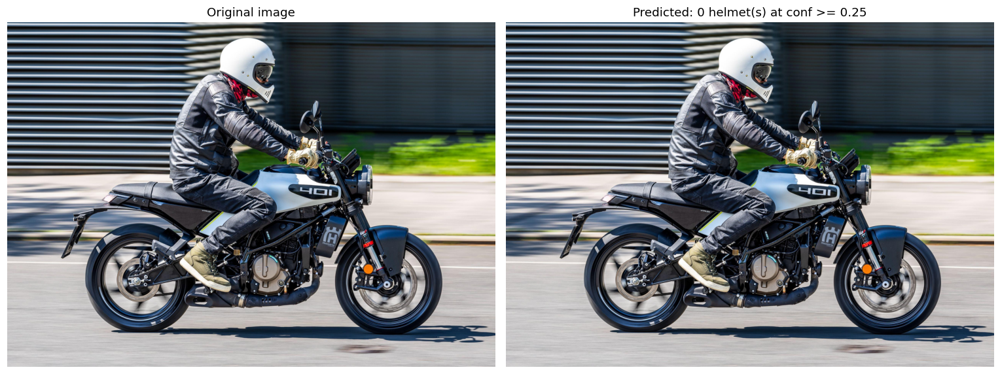

No helmets detected. Try a lower confidence threshold.
Saved: /content/Helmet_Detection/outputs/bike_detected.jpg

===== helmet.jpg =====


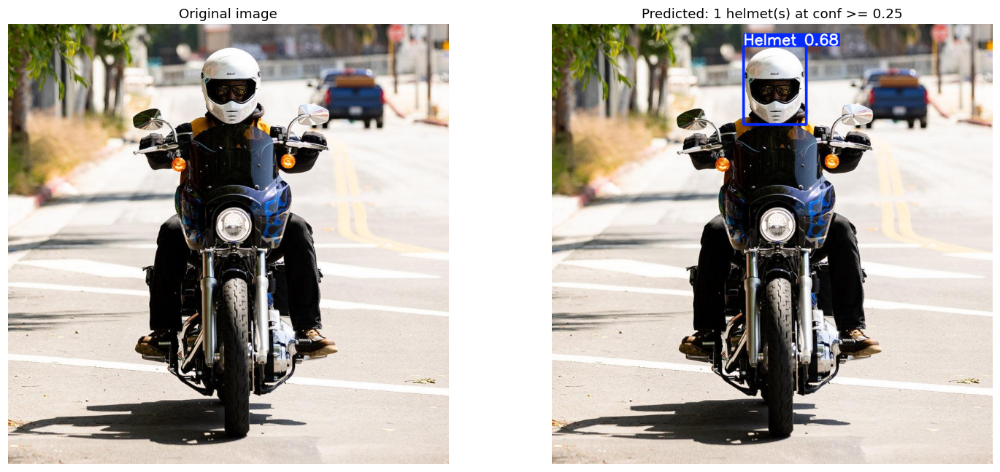

,class,confidence,"box (x1,y1,x2,y2)"
0,Helmet,0.675,"391.7, 44.5, 519.0, 205.1"


Saved: /content/Helmet_Detection/outputs/helmet_detected.jpg


In [12]:
from google.colab import files
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

IMAGE_CONF = 0.25            # <- change this threshold (0.05 to 0.95)
REUSE_LAST_UPLOAD = False    # True = reuse the previously uploaded images

if not BEST_PT.exists():
    raise FileNotFoundError(f"{BEST_PT} not found. Run Section 9 first.")
infer_model = YOLO(str(BEST_PT))

def run_image_detection(image_path, conf=0.25, save=True):
    image_path = Path(image_path)
    try:
        original = ImageOps.exif_transpose(Image.open(image_path)).convert("RGB")
    except Exception as e:
        print(f"Cannot read image '{image_path.name}': {e}")
        return None
    result = infer_model.predict(source=original, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    annotated = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)        # plot() returns BGR -> convert to RGB
    detections = []
    for b in result.boxes:
        x1, y1, x2, y2 = [round(float(v), 1) for v in b.xyxy[0].tolist()]
        detections.append({"class": result.names[int(b.cls[0])], "confidence": round(float(b.conf[0]), 3),
                           "box (x1,y1,x2,y2)": f"{x1}, {y1}, {x2}, {y2}"})
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    ax[0].imshow(original); ax[0].set_title("Original image"); ax[0].axis("off")
    ax[1].imshow(annotated); ax[1].set_title(f"Predicted: {len(detections)} helmet(s) at conf >= {conf}"); ax[1].axis("off")
    plt.tight_layout(); plt.show()
    if detections:
        display(pd.DataFrame(detections))
    else:
        print("No helmets detected. Try a lower confidence threshold.")
    if save:
        out = OUTPUT_DIR / f"{image_path.stem}_detected.jpg"
        if cv2.imwrite(str(out), cv2.cvtColor(annotated, cv2.COLOR_RGB2BGR)):
            print("Saved:", out)
        else:
            print("WARNING: could not save", out)
    return detections

if REUSE_LAST_UPLOAD and globals().get("LAST_IMAGES"):
    image_paths = LAST_IMAGES
else:
    print("Choose one or more images (JPG/PNG)...")
    up = files.upload()
    image_paths = []
    for name in up:
        if Path(name).suffix.lower() in IMG_EXTS:
            src = Path.cwd() / name
            dest = OUTPUT_DIR / Path(name).name
            if src.exists():
                shutil.move(str(src), str(dest))
            image_paths.append(dest)
        else:
            print(f"Skipped '{name}': not an image file ({sorted(IMG_EXTS)}).")
    if not image_paths:
        demo = random.choice(FINAL_SCAN["test"]["pairs"])["img"]
        print(f"No valid image uploaded -> using a random TEST image as a demo: {demo.name}")
        image_paths = [demo]
    LAST_IMAGES = image_paths

for pth in image_paths:
    print("\n=====", Path(pth).name, "=====")
    run_image_detection(pth, conf=IMAGE_CONF)

In [15]:
import base64, subprocess
from IPython.display import HTML, display as ipy_display

VIDEO_CONF = 0.25
MAX_SECONDS = None          # e.g. 20 to process only the first 20 seconds
ALLOWED_VIDEO = {".mp4", ".avi", ".mov"}

def process_video(in_path, out_path, conf=0.25, max_seconds=None):
    in_path, out_path = Path(in_path), Path(out_path)
    if in_path.suffix.lower() not in ALLOWED_VIDEO:
        raise ValueError(f"Unsupported video format '{in_path.suffix}'. Use one of {sorted(ALLOWED_VIDEO)}.")
    cap = cv2.VideoCapture(str(in_path))
    if not cap.isOpened():
        raise IOError("OpenCV cannot open this video (damaged file or missing codec). "
                      "Convert it to MP4 (H.264) and try again.")
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps != fps or fps <= 0 or fps > 240:
        fps = 25.0
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    ok, frame = cap.read()
    if not ok:
        cap.release()
        raise IOError("The video opened but no frames could be read (unsupported codec or empty file).")
    h, w = frame.shape[:2]
    raw_path = out_path.with_name(out_path.stem + "_raw.mp4")
    writer = cv2.VideoWriter(str(raw_path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    if not writer.isOpened():
        cap.release()
        raise IOError("Could not create the output video file (codec 'mp4v' unavailable).")
    limit = int(max_seconds * fps) if max_seconds else None
    n_frames, n_det, t0 = 0, 0, time.time()
    try:
        while ok:
            res = infer_model.predict(source=frame, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
            n_det += len(res.boxes)
            writer.write(res.plot())                                    # BGR frame with boxes + labels
            n_frames += 1
            if n_frames % 30 == 0:
                print(f"  processed {n_frames}" + (f"/{total}" if total > 0 else "") + " frames ...")
            if limit and n_frames >= limit:
                print(f"  stopped at MAX_SECONDS = {max_seconds}")
                break
            ok, frame = cap.read()
    finally:
        cap.release(); writer.release()
    secs = time.time() - t0
    summary = {"frames": n_frames, "detections": n_det, "avg_per_frame": round(n_det / max(n_frames, 1), 2),
               "seconds": round(secs, 1), "fps_processing": round(n_frames / max(secs, 1e-6), 1)}

    final_path = raw_path                                               # fallback if ffmpeg is unavailable
    if shutil.which("ffmpeg"):
        cmd = ["ffmpeg", "-y", "-loglevel", "error", "-i", str(raw_path), "-vcodec", "libx264",
               "-pix_fmt", "yuv420p", "-vf", "scale=trunc(iw/2)*2:trunc(ih/2)*2", "-movflags", "+faststart",
               str(out_path)]
        r = subprocess.run(cmd, capture_output=True, text=True)
        if r.returncode == 0 and out_path.exists():
            final_path = out_path
        else:
            print("WARNING: ffmpeg conversion failed; using the raw mp4v file instead.\n", r.stderr[-500:])
    else:
        print("WARNING: ffmpeg not found; the raw mp4v file may not play in the browser (you can still download it).")
    return final_path, summary

print("Choose a video file (MP4, AVI or MOV)...")
up_vid = files.upload()
vid_names = list(up_vid)
if not vid_names:
    raise FileNotFoundError("No video uploaded. Run this cell again and select a video.")
VIDEO_IN = Path.cwd() / vid_names[0]
VIDEO_OUT = OUTPUT_DIR / (VIDEO_IN.stem + "_detected.mp4")

try:
    VIDEO_RESULT, VIDEO_SUMMARY = process_video(VIDEO_IN, VIDEO_OUT, conf=VIDEO_CONF, max_seconds=MAX_SECONDS)
except (ValueError, IOError) as e:
    VIDEO_RESULT = None
    print("VIDEO ERROR:", e)

if VIDEO_RESULT is not None:
    print("\nSummary:", VIDEO_SUMMARY)
    print("Saved:", VIDEO_RESULT, f"({VIDEO_RESULT.stat().st_size / 1024**2:.1f} MB)")
    if VIDEO_RESULT.stat().st_size < 40 * 1024**2:
        b64 = base64.b64encode(VIDEO_RESULT.read_bytes()).decode()
        ipy_display(HTML(f'<video width="720" controls><source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>'))
    else:
        print("The video is large, so it is not embedded. Download it with: files.download(str(VIDEO_RESULT))")

Choose a video file (MP4, AVI or MOV)...


Saving 14293754_1080_1920_30fps.mp4 to 14293754_1080_1920_30fps.mp4
  processed 30/333 frames ...
  processed 60/333 frames ...
  processed 90/333 frames ...
  processed 120/333 frames ...
  processed 150/333 frames ...
  processed 180/333 frames ...
  processed 210/333 frames ...
  processed 240/333 frames ...
  processed 270/333 frames ...
  processed 300/333 frames ...
  processed 330/333 frames ...

Summary: {'frames': 333, 'detections': 32, 'avg_per_frame': 0.1, 'seconds': 11.8, 'fps_processing': 28.1}
Saved: /content/Helmet_Detection/outputs/14293754_1080_1920_30fps_detected.mp4 (4.8 MB)


In [16]:
final_model = YOLO(str(BEST_PT))
print("best.pt path :", BEST_PT)
print("best.pt size :", f"{BEST_PT.stat().st_size / 1024**2:.2f} MB")
print("Class names  :", final_model.names)
assert list(final_model.names.values()) == CLASS_NAMES, "Model class names do not match data.yaml!"

try:
    onnx_path = final_model.export(format="onnx", imgsz=IMGSZ)
    target = MODELS_DIR / Path(onnx_path).name
    if Path(onnx_path).resolve() != target.resolve():
        shutil.copy2(onnx_path, target)
    print("Saved ONNX   :", target)
except Exception as e:
    print("ONNX export skipped (optional step):", str(e)[:300])

print("\nFiles in", MODELS_DIR)
for f in sorted(MODELS_DIR.iterdir()):
    print("  ", f.name, f"{f.stat().st_size / 1024**2:.2f} MB")

best.pt path : /content/Helmet_Detection/models/best.pt
best.pt size : 6.21 MB
Class names  : {0: 'Helmet'}
Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/Helmet_Detection/models/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (6.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 712ms
Prepared 4 packages in 1.09s
Installed 4 packages in 124ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.1
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 2.9s
WARNING ⚠️ requirements: Restart runtime or rerun co

In [18]:
import importlib.metadata as md_

PROJECT_NAME = "Helmet-Detection-Using-Custom-YOLO"
PROJ = BASE / PROJECT_NAME
if not BEST_PT.exists():
    raise FileNotFoundError(f"{BEST_PT} not found. Run Section 9 first.")
if PROJ.exists():
    shutil.rmtree(PROJ)
for sub in ("training", "inference", "outputs", "screenshots"):
    (PROJ / sub).mkdir(parents=True, exist_ok=True)

ULTRA_VER = md_.version("ultralytics")

# =============================== app.py =====================================
APP_PY = r'''
import os
import shutil
import subprocess
import tempfile
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import streamlit as st
from PIL import Image, ImageOps
from ultralytics import YOLO

APP_DIR = Path(__file__).resolve().parent
MODEL_PATH = APP_DIR / "best.pt"
IMAGE_TYPES = ["jpg", "jpeg", "png", "bmp", "webp"]
VIDEO_TYPES = ["mp4", "avi", "mov"]

st.set_page_config(page_title="Helmet Detection using Custom YOLO", page_icon="🪖", layout="wide")


@st.cache_resource(show_spinner="Loading YOLO model ...")
def load_model(path):
    return YOLO(path)


def to_png_bytes(rgb_array):
    ok, buf = cv2.imencode(".png", cv2.cvtColor(rgb_array, cv2.COLOR_RGB2BGR))
    if not ok:
        raise ValueError("Could not encode the image.")
    return buf.tobytes()


def detections_table(result):
    rows = []
    for b in result.boxes:
        x1, y1, x2, y2 = [round(float(v), 1) for v in b.xyxy[0].tolist()]
        rows.append({"Class": result.names[int(b.cls[0])], "Confidence": round(float(b.conf[0]), 3),
                     "x1": x1, "y1": y1, "x2": x2, "y2": y2})
    return pd.DataFrame(rows)


def process_video(model, in_path, out_path, conf, max_frames, progress):
    cap = cv2.VideoCapture(str(in_path))
    if not cap.isOpened():
        raise IOError("This video cannot be opened (damaged file or unsupported codec). Try converting it to MP4.")
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps != fps or fps <= 0 or fps > 240:
        fps = 25.0
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    ok, frame = cap.read()
    if not ok:
        cap.release()
        raise IOError("No frames could be read from this video.")
    h, w = frame.shape[:2]
    raw_path = Path(out_path).with_name("raw_" + Path(out_path).name)
    writer = cv2.VideoWriter(str(raw_path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    if not writer.isOpened():
        cap.release()
        raise IOError("Could not create the output video.")
    n, n_det = 0, 0
    target = min(total, max_frames) if total > 0 else max_frames
    try:
        while ok and n < max_frames:
            res = model.predict(source=frame, conf=conf, verbose=False)[0]
            n_det += len(res.boxes)
            writer.write(res.plot())
            n += 1
            progress.progress(min(n / max(target, 1), 1.0), text=f"Processing frame {n} of {target}")
            ok, frame = cap.read()
    finally:
        cap.release()
        writer.release()
    final = raw_path
    if shutil.which("ffmpeg"):
        cmd = ["ffmpeg", "-y", "-loglevel", "error", "-i", str(raw_path), "-vcodec", "libx264",
               "-pix_fmt", "yuv420p", "-vf", "scale=trunc(iw/2)*2:trunc(ih/2)*2", "-movflags", "+faststart",
               str(out_path)]
        if subprocess.run(cmd, capture_output=True).returncode == 0 and Path(out_path).exists():
            final = Path(out_path)
    return final, n, n_det, final != raw_path


# ----------------------------- page header ---------------------------------
st.title("🪖 Helmet Detection Using Custom YOLO")
st.markdown(
    "Detects **helmets** worn by two-wheeler riders in images and videos using a custom-trained "
    "**YOLOv8** model (transfer learning from `yolov8n.pt`)."
)
st.info(
    "This model has a single class: **Helmet**. It finds helmets and draws boxes around them. "
    "It does **not** classify riders as 'without helmet'; that would need extra labelled data."
)

if not MODEL_PATH.exists():
    st.error(f"Model file not found: `{MODEL_PATH.name}`. Place your trained `best.pt` next to `app.py`.")
    st.stop()

try:
    model = load_model(str(MODEL_PATH))
except Exception as exc:
    st.error(f"The model could not be loaded: {exc}")
    st.stop()

with st.sidebar:
    st.header("Settings")
    conf = st.slider("Confidence threshold", 0.05, 0.95, 0.25, 0.05,
                     help="Lower = more boxes (more false alarms). Higher = fewer but surer boxes.")
    st.caption("Model classes: " + ", ".join(str(v) for v in model.names.values()))

tab_img, tab_vid = st.tabs(["🖼️ Image detection", "🎬 Video detection"])

# ----------------------------- image tab -----------------------------------
with tab_img:
    up = st.file_uploader("Upload an image", type=IMAGE_TYPES, key="img")
    if up is not None:
        try:
            image = ImageOps.exif_transpose(Image.open(up)).convert("RGB")   # PIL image is RGB
        except Exception as exc:
            st.error(f"This file could not be read as an image: {exc}")
        else:
            with st.spinner("Detecting helmets ..."):
                try:
                    result = model.predict(source=image, conf=conf, verbose=False)[0]
                except Exception as exc:
                    st.error(f"Detection failed: {exc}")
                    st.stop()
            annotated_rgb = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)   # plot() is BGR -> RGB for display
            c1, c2 = st.columns(2)
            c1.subheader("Original")
            c1.image(image)
            c2.subheader("Detected")
            c2.image(annotated_rgb)
            table = detections_table(result)
            st.subheader("Detection summary")
            m1, m2 = st.columns(2)
            m1.metric("Helmets detected", len(table))
            m2.metric("Average confidence", f"{table['Confidence'].mean():.2f}" if len(table) else "n/a")
            if len(table):
                st.dataframe(table)
            else:
                st.warning("No helmets detected at this threshold. Try lowering the confidence slider.")
            st.download_button("Download annotated image", to_png_bytes(annotated_rgb),
                               file_name="helmet_detection.png", mime="image/png")

# ----------------------------- video tab -----------------------------------
with tab_vid:
    max_frames = st.slider("Maximum frames to process", 30, 1000, 300, 30,
                           help="Limits processing time, especially on the free cloud CPU.")
    vup = st.file_uploader("Upload a video (MP4, AVI, MOV)", type=VIDEO_TYPES, key="vid")
    if vup is not None:
        tmp_dir = tempfile.mkdtemp()
        in_path = os.path.join(tmp_dir, "input" + Path(vup.name).suffix.lower())
        out_path = os.path.join(tmp_dir, "helmet_detection_output.mp4")
        with open(in_path, "wb") as f:
            f.write(vup.getbuffer())
        progress = st.progress(0.0, text="Starting ...")
        try:
            t0 = time.time()
            final, n_frames, n_det, playable = process_video(model, in_path, out_path, conf, max_frames, progress)
        except Exception as exc:
            st.error(f"Video processing failed: {exc}")
        else:
            progress.empty()
            st.success(f"Processed {n_frames} frames in {time.time() - t0:.1f} s")
            s1, s2, s3 = st.columns(3)
            s1.metric("Frames processed", n_frames)
            s2.metric("Total detections", n_det)
            s3.metric("Avg detections / frame", f"{n_det / max(n_frames, 1):.2f}")
            data = Path(final).read_bytes()
            if playable:
                st.video(data)
            else:
                st.warning("ffmpeg is not available, so the video cannot be previewed here. Use the download button.")
            st.download_button("Download processed video", data, file_name="helmet_detection_output.mp4",
                               mime="video/mp4")
        finally:
            shutil.rmtree(tmp_dir, ignore_errors=True)

st.markdown("---")
st.caption("Built with Ultralytics YOLOv8 and Streamlit | Academic project: Helmet Detection Using Custom YOLO")
'''
(PROJ / "app.py").write_text(APP_PY.lstrip("\n"), encoding="utf-8")

# =============================== requirements / packages / gitignore =========
REQ = (
    "# CPU-only PyTorch keeps the Streamlit Cloud install small\n"
    "--extra-index-url https://download.pytorch.org/whl/cpu\n"
    "torch\n"
    "torchvision\n"
    f"ultralytics=={ULTRA_VER}\n"
    "streamlit>=1.35\n"
    "opencv-python-headless\n"
    "numpy\n"
    "pandas\n"
    "pillow\n"
    "pyyaml\n"
    "matplotlib\n"
)
(PROJ / "requirements.txt").write_text(REQ, encoding="utf-8")
(PROJ / "packages.txt").write_text("ffmpeg\nlibgl1\n", encoding="utf-8")
(PROJ / ".gitignore").write_text("__pycache__/\n*.pyc\n.venv/\nruns/\n*.zip\nhelmet_dataset/\nhelmet_split/\n", encoding="utf-8")

# =============================== training/train.py ==========================
TRAIN_PY = r'''
# Standalone training script (the notebook does the same thing step by step).
# Usage:  python training/train.py --data /path/to/data.yaml
import argparse
from pathlib import Path

import torch
from ultralytics import YOLO


def auto_batch():
    if not torch.cuda.is_available():
        return 4
    gb = torch.cuda.get_device_properties(0).total_memory / 1024 ** 3
    return 32 if gb >= 14 else 16 if gb >= 8 else 8


def main():
    ap = argparse.ArgumentParser(description="Train a custom YOLOv8 helmet detector")
    ap.add_argument("--data", required=True, help="path to data.yaml")
    ap.add_argument("--model", default="yolov8n.pt")
    ap.add_argument("--epochs", type=int, default=50)
    ap.add_argument("--imgsz", type=int, default=640)
    ap.add_argument("--batch", type=int, default=0, help="0 = choose automatically from GPU memory")
    ap.add_argument("--workers", type=int, default=2)
    ap.add_argument("--patience", type=int, default=15)
    ap.add_argument("--project", default="Helmet_Detection")
    ap.add_argument("--name", default="custom_yolov8")
    args = ap.parse_args()

    if not Path(args.data).exists():
        raise FileNotFoundError(f"data.yaml not found: {args.data}")
    batch = args.batch or auto_batch()
    device = 0 if torch.cuda.is_available() else "cpu"
    print(f"device={device} batch={batch}")

    while True:
        try:
            model = YOLO(args.model)
            model.train(data=args.data, epochs=args.epochs, imgsz=args.imgsz, batch=batch,
                        workers=args.workers, device=device, patience=args.patience, optimizer="auto",
                        project=str(Path(args.project).resolve()), name=args.name, exist_ok=True, seed=0)
            break
        except Exception as err:
            if ("out of memory" in str(err).lower()) and batch > 2:
                batch //= 2
                print(f"CUDA out of memory -> retrying with batch={batch}")
                torch.cuda.empty_cache()
                continue
            raise
    print("Training finished. Weights are in:", model.trainer.save_dir)


if __name__ == "__main__":
    main()
'''
(PROJ / "training" / "train.py").write_text(TRAIN_PY.lstrip("\n"), encoding="utf-8")

# =============================== inference/image_detection.py ===============
IMG_PY = r'''
# Usage:  python inference/image_detection.py --source photo.jpg --conf 0.25
import argparse
from pathlib import Path

import cv2
from PIL import Image, ImageOps
from ultralytics import YOLO


def main():
    root = Path(__file__).resolve().parent.parent
    ap = argparse.ArgumentParser(description="Helmet detection on one image")
    ap.add_argument("--source", required=True, help="path to an image")
    ap.add_argument("--weights", default=str(root / "best.pt"))
    ap.add_argument("--conf", type=float, default=0.25)
    ap.add_argument("--output", default=str(root / "outputs"))
    args = ap.parse_args()

    src, weights = Path(args.source), Path(args.weights)
    if not src.exists():
        raise FileNotFoundError(f"Image not found: {src}")
    if not weights.exists():
        raise FileNotFoundError(f"Weights not found: {weights}")
    try:
        image = ImageOps.exif_transpose(Image.open(src)).convert("RGB")
    except Exception as exc:
        raise SystemExit(f"Cannot read image: {exc}")

    model = YOLO(str(weights))
    result = model.predict(source=image, conf=args.conf, verbose=False)[0]
    print(f"Helmets detected: {len(result.boxes)}")
    for b in result.boxes:
        print(f"  {result.names[int(b.cls[0])]}  conf={float(b.conf[0]):.3f}  box={[round(v, 1) for v in b.xyxy[0].tolist()]}")
    out_dir = Path(args.output)
    out_dir.mkdir(parents=True, exist_ok=True)
    out = out_dir / f"{src.stem}_detected.jpg"
    if not cv2.imwrite(str(out), result.plot()):
        raise SystemExit(f"Could not save {out}")
    print("Saved:", out)


if __name__ == "__main__":
    main()
'''
(PROJ / "inference" / "image_detection.py").write_text(IMG_PY.lstrip("\n"), encoding="utf-8")

# =============================== inference/video_detection.py ===============
VID_PY = r'''
# Usage:  python inference/video_detection.py --source clip.mp4 --conf 0.25
import argparse
from pathlib import Path

import cv2
from ultralytics import YOLO


def main():
    root = Path(__file__).resolve().parent.parent
    ap = argparse.ArgumentParser(description="Helmet detection on a video")
    ap.add_argument("--source", required=True, help="path to .mp4 / .avi / .mov")
    ap.add_argument("--weights", default=str(root / "best.pt"))
    ap.add_argument("--conf", type=float, default=0.25)
    ap.add_argument("--output", default=str(root / "outputs"))
    args = ap.parse_args()

    src, weights = Path(args.source), Path(args.weights)
    if src.suffix.lower() not in {".mp4", ".avi", ".mov"}:
        raise SystemExit(f"Unsupported video format {src.suffix}. Use .mp4, .avi or .mov")
    if not src.exists():
        raise FileNotFoundError(f"Video not found: {src}")
    if not weights.exists():
        raise FileNotFoundError(f"Weights not found: {weights}")

    cap = cv2.VideoCapture(str(src))
    if not cap.isOpened():
        raise SystemExit("Cannot open the video (damaged file or missing codec).")
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps != fps or fps <= 0 or fps > 240:
        fps = 25.0
    ok, frame = cap.read()
    if not ok:
        raise SystemExit("No frames could be read from the video.")
    h, w = frame.shape[:2]

    out_dir = Path(args.output)
    out_dir.mkdir(parents=True, exist_ok=True)
    out = out_dir / f"{src.stem}_detected.mp4"
    writer = cv2.VideoWriter(str(out), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    if not writer.isOpened():
        raise SystemExit("Could not create the output video file.")

    model = YOLO(str(weights))
    n, total = 0, 0
    while ok:
        res = model.predict(source=frame, conf=args.conf, verbose=False)[0]
        total += len(res.boxes)
        writer.write(res.plot())
        n += 1
        if n % 30 == 0:
            print(f"processed {n} frames")
        ok, frame = cap.read()
    cap.release()
    writer.release()
    print(f"Done: {n} frames, {total} detections. Saved: {out}")


if __name__ == "__main__":
    main()
'''
(PROJ / "inference" / "video_detection.py").write_text(VID_PY.lstrip("\n"), encoding="utf-8")

# =============================== README.md ==================================
def fmt_metric(d, k):
    return f"{d[k]:.4f}" if d and k in d else "not available (run Section 10)"

tm = globals().get("TEST_METRICS"); vm = globals().get("VAL_METRICS")
stats = globals().get("DATA_STATS")
if stats:
    orig_line = (f"The downloaded ZIP contained {stats['original_images']} images, split by Roboflow as "
                 + ", ".join(f"{k}: {v}" for k, v in stats["original_split"].items())
                 + (". That split was kept." if stats["kept_original_split"] else
                    ". It was not 70:20:10 (and some source photos appeared in more than one split), so a new "
                    "reproducible split (seed 42, grouped by source photo) was created."))
    split_tbl = "\n".join(f"| {s} | {stats['images'][s]} | {stats['boxes'][s]} |" for s in stats["images"])
else:
    orig_line, split_tbl = "Dataset statistics not available (run Sections 5-7).", "| - | - | - |"

if tm:
    results_tbl = ("| Metric | Test set | Validation set |\n|---|---|---|\n" +
                   "\n".join(f"| {k} | {fmt_metric(tm, k)} | {fmt_metric(vm, k)} |" for k in tm))
else:
    results_tbl = "Evaluation results are not available. Run Section 10 of the notebook and regenerate this README."

epochs_done = "see results.csv"
try:
    epochs_done = str(int(pd.read_csv(SAVE_DIR / "results.csv").rename(columns=str.strip)["epoch"].max()))
except Exception:
    pass
params_txt = f"{globals().get('MODEL_PARAMS'):,}" if globals().get("MODEL_PARAMS") else "n/a"

README = r'''
# Helmet Detection Using Custom YOLO

## 1. Project overview
A custom-trained **YOLOv8** object detector that finds **helmets worn by two-wheeler riders** in images and videos. It draws bounding boxes with the class name and confidence score, and ships with a **Streamlit** web app.

## 2. Problem statement
Riding without a helmet is a major cause of fatal two-wheeler accidents. Manual monitoring is slow and error-prone. This project builds an automatic, camera-based helmet detector as a first step towards helmet-compliance monitoring.

## 3. Objectives
- Train a custom YOLO model (transfer learning) to detect helmets.
- Evaluate it on a held-out test set with standard metrics.
- Run detection on images and videos.
- Provide a Streamlit app for easy use and deployment.

## 4. Technologies used
Python, Google Colab, PyTorch, Ultralytics YOLOv8, OpenCV, Pillow, NumPy, Pandas, Matplotlib, Streamlit, GitHub.

## 5. Dataset
- **Source:** Roboflow Universe, project `helmet-motorcycle-detection-pro0q` (workspace `computer-vision-vxgzc`), version 1. https://universe.roboflow.com/computer-vision-vxgzc/helmet-motorcycle-detection-pro0q
- **License:** as stated in the dataset's `data.yaml` / README (Public Domain at the time of download).
- **Format:** YOLOv8 (one `.txt` label file per image).
- **Classes:** @@CLASSES@@
- **Important limitation:** the dataset has only the class *Helmet*. The model detects helmets; it **cannot** detect riders *without* helmets. That needs extra, properly labelled "No Helmet" data.
- Roboflow pre-processing: auto-orient, resize to 640x640 (stretch). Training images were augmented by Roboflow (flip, 90-degree rotation, blur, noise), creating about 3 copies per source photo.

## 6. Dataset splitting
@@ORIGLINE@@

Final split used for training/evaluation (target 70% / 20% / 10%):

| Split | Images | Helmet boxes |
|---|---|---|
@@SPLITTBL@@

## 7. YOLO architecture
YOLOv8n (nano) from Ultralytics: a CSP-style convolutional backbone for feature extraction, a PAN/FPN neck that merges features from several scales, and an anchor-free decoupled head that predicts box position and class separately. The model has about @@PARAMS@@ parameters. Training started from COCO-pretrained `yolov8n.pt` (transfer learning).

## 8. Training configuration
| Setting | Value |
|---|---|
| Base weights | yolov8n.pt (pretrained) |
| Max epochs | @@EPOCHS@@ (early stopping patience: @@PATIENCE@@) |
| Epochs actually trained | @@EPOCHSDONE@@ |
| Image size | @@IMGSZ@@ |
| Batch size | @@BATCH@@ |
| Optimizer | auto |
| Workers | 2 |
| Ultralytics version | @@ULTRA@@ |
| Project / run name | Helmet_Detection / custom_yolov8 |

## 9. Evaluation metrics
- **Precision** - of the boxes drawn, the fraction that are real helmets.
- **Recall** - of the real helmets, the fraction found.
- **mAP50** - mean average precision at IoU 0.50.
- **mAP50-95** - mean average precision averaged over IoU 0.50 to 0.95 (stricter).

## 10. Results
Values below were produced by the notebook (Section 10). Precision and recall are reported at the confidence threshold that maximizes F1.

@@RESULTS@@

Plots (confusion matrix, PR curve, F1 curve, training curves) are in the `screenshots/` folder.

*Caveat:* validation and test images include Roboflow-augmented copies, and the dataset is small, so real-world performance on new cameras, lighting and angles may be lower than these numbers.

## 11. How to run locally
```bash
git clone <YOUR-GITHUB-REPO-URL>
cd Helmet-Detection-Using-Custom-YOLO
python -m venv .venv
source .venv/bin/activate        # Windows: .venv\Scripts\activate
pip install -r requirements.txt
streamlit run app.py
```
Command-line detection:
```bash
python inference/image_detection.py --source path/to/image.jpg --conf 0.25
python inference/video_detection.py --source path/to/video.mp4 --conf 0.25
```
Retrain (needs the dataset and a `data.yaml`): `python training/train.py --data path/to/data.yaml`

## 12. Streamlit Community Cloud deployment
1. Push this folder to a **public** GitHub repository (include `best.pt`, `app.py`, `requirements.txt`, `packages.txt`).
2. Go to https://share.streamlit.io and sign in with GitHub.
3. Click **Create app**, choose the repository and branch, set the main file path to `app.py`.
4. Click **Deploy** and wait for the build (first build takes a few minutes).

## 13. Links (placeholders - not deployed yet)
- GitHub repository: `<ADD YOUR GITHUB REPOSITORY LINK HERE>`
- Streamlit application: `<ADD YOUR STREAMLIT APP LINK HERE AFTER DEPLOYMENT>`
- Hugging Face Space: `<ADD YOUR HUGGING FACE SPACE LINK HERE IF YOU DEPLOY THERE>`

## 14. Conclusion
A one-class YOLOv8n helmet detector was trained with transfer learning and evaluated on a held-out test split (see Results above). The app can detect helmets in images and videos. Future work: add a labelled "No Helmet" class, add number-plate recognition for enforcement, collect more varied data (night, rain, different cities), and test on real traffic video.
'''
for key, val in {"@@CLASSES@@": ", ".join(f"`{n}` (ID {i})" for i, n in enumerate(CLASS_NAMES)),
                 "@@ORIGLINE@@": orig_line, "@@SPLITTBL@@": split_tbl, "@@PARAMS@@": params_txt,
                 "@@EPOCHS@@": str(EPOCHS), "@@PATIENCE@@": str(PATIENCE), "@@EPOCHSDONE@@": epochs_done,
                 "@@IMGSZ@@": str(IMGSZ), "@@BATCH@@": str(BATCH), "@@ULTRA@@": ULTRA_VER,
                 "@@RESULTS@@": results_tbl}.items():
    README = README.replace(key, val)
(PROJ / "README.md").write_text(README.lstrip("\n"), encoding="utf-8")

# =============================== copy weights, figures, samples ==============
shutil.copy2(BEST_PT, PROJ / "best.pt")
n_fig = 0
for png in list(FIG_DIR.glob("*.png")) + [RESULTS_SAVE / "results.png"]:
    if png.exists():
        shutil.copy2(png, PROJ / "screenshots" / png.name); n_fig += 1
n_out = 0
for f in OUTPUT_DIR.glob("*_detected.jpg"):                       # sample images only (videos are too big for GitHub)
    shutil.copy2(f, PROJ / "outputs" / f.name); n_out += 1
(PROJ / "outputs" / ".gitkeep").touch()
(PROJ / "screenshots" / ".gitkeep").touch()
print(f"Copied best.pt, {n_fig} figure(s) and {n_out} sample output(s).\n")

# ---- syntax-check the generated Python files, then print the tree ----
for py in PROJ.rglob("*.py"):
    compile(py.read_text(encoding="utf-8"), str(py), "exec")      # raises SyntaxError if broken (writes no files)
print("All generated .py files compile without syntax errors.\n")
print(PROJECT_NAME + "/")
for p in sorted(PROJ.rglob("*")):
    if p.is_file() and "__pycache__" not in p.parts:
        print("   ", p.relative_to(PROJ), f"({p.stat().st_size / 1024:.1f} KB)")

Copied best.pt, 12 figure(s) and 2 sample output(s).

All generated .py files compile without syntax errors.

Helmet-Detection-Using-Custom-YOLO/
    .gitignore (0.1 KB)
    README.md (5.3 KB)
    app.py (7.5 KB)
    best.pt (6354.0 KB)
    inference/image_detection.py (1.6 KB)
    inference/video_detection.py (2.1 KB)
    outputs/.gitkeep (0.0 KB)
    outputs/bike_detected.jpg (1081.3 KB)
    outputs/helmet_detected.jpg (226.6 KB)
    packages.txt (0.0 KB)
    requirements.txt (0.2 KB)
    screenshots/.gitkeep (0.0 KB)
    screenshots/01_sample_images.png (2316.8 KB)
    screenshots/02_class_distribution.png (26.2 KB)
    screenshots/03_split_statistics.png (47.2 KB)
    screenshots/04_boxes_per_image.png (23.5 KB)
    screenshots/confusion_matrix_test_set.png (27.8 KB)
    screenshots/f1_curve_test_set.png (40.6 KB)
    screenshots/normalized_confusion_matrix_test_set.png (29.1 KB)
    screenshots/precision_confidence_curve_test_set.png (38.9 KB)
    screenshots/precision_recall_curv

In [19]:
if not PROJ.exists():
    raise FileNotFoundError("Project folder not found. Run Section 14 first.")

PROJECT_ZIP = Path(shutil.make_archive(str(BASE / PROJECT_NAME), "zip", root_dir=BASE, base_dir=PROJECT_NAME))
with zipfile.ZipFile(PROJECT_ZIP) as z:
    names = z.namelist()
    if any("helmet_dataset" in n or "helmet_split" in n for n in names):
        raise RuntimeError("The dataset was included in the ZIP by mistake.")
print(f"Created: {PROJECT_ZIP}  ({PROJECT_ZIP.stat().st_size / 1024**2:.1f} MB), {len(names)} entries")
for n in names:
    if not n.endswith("/"):
        print("  ", n)

try:
    files.download(str(PROJECT_ZIP))
except Exception as e:
    print("Automatic download did not start:", e)
    print("Download it manually from the Colab file browser:", PROJECT_ZIP)

Created: /content/Helmet-Detection-Using-Custom-YOLO.zip  (9.7 MB), 30 entries
   Helmet-Detection-Using-Custom-YOLO/README.md
   Helmet-Detection-Using-Custom-YOLO/app.py
   Helmet-Detection-Using-Custom-YOLO/packages.txt
   Helmet-Detection-Using-Custom-YOLO/best.pt
   Helmet-Detection-Using-Custom-YOLO/.gitignore
   Helmet-Detection-Using-Custom-YOLO/requirements.txt
   Helmet-Detection-Using-Custom-YOLO/screenshots/04_boxes_per_image.png
   Helmet-Detection-Using-Custom-YOLO/screenshots/02_class_distribution.png
   Helmet-Detection-Using-Custom-YOLO/screenshots/precision_confidence_curve_test_set.png
   Helmet-Detection-Using-Custom-YOLO/screenshots/03_split_statistics.png
   Helmet-Detection-Using-Custom-YOLO/screenshots/recall_confidence_curve_test_set.png
   Helmet-Detection-Using-Custom-YOLO/screenshots/normalized_confusion_matrix_test_set.png
   Helmet-Detection-Using-Custom-YOLO/screenshots/training_curves.png
   Helmet-Detection-Using-Custom-YOLO/screenshots/precision_recall

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>